# Compare temperature power and modal EAPE growth

RH increases across columns. Experiment figures group rows by qflux, with
original radiation followed by locked radiation for each qflux value.
Difference figures show locked minus original, with qflux in rows and the
same RH columns. Each figure has shared axes and one common color scale.

The notebook includes log10 temperature power, sigma1 and sigma2 heating
contributions to EAPE growth, and the radiation differences for all three
quantities. The sigma sections follow the temperature-power figures.
The temperature-power differences include contours of the matching
original-radiation log10 power spectrum.

## Import packages

In [1]:
import json
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm

## Load saved experiment spectra

In [2]:
DATAPATH = Path("/home/b11209013/Isca_analysis/Output/EAPE_budget")
files = sorted(DATAPATH.glob("*_eape.npz"))
if not files:
    raise FileNotFoundError(f"No *_eape.npz files found in {DATAPATH}")

temp_power = {}
sigma1 = {}
sigma2 = {}
experiment_info = {}

for file in files:
    with np.load(file, allow_pickle=False) as data:
        exp_name = file.stem.removesuffix("_eape")
        file_freq = data["frequency"]
        file_wnum = data["wavenumber"]
        if not temp_power:
            freq, wnum = file_freq.copy(), file_wnum.copy()
        elif not (
            np.array_equal(freq, file_freq) and np.array_equal(wnum, file_wnum)
        ):
            raise ValueError(f"Frequency/wavenumber grid differs in {file.name}")

        power = data["temperature_power"]
        if power.shape != (freq.size, wnum.size):
            raise ValueError(f"Unexpected temperature-power shape in {file.name}")
        temp_power[exp_name] = power
        sigma1[exp_name] = data["sigma_1"]
        sigma2[exp_name] = data["sigma_2"]
        experiment_info[exp_name] = json.loads(data["metadata"].item())

print(f"Loaded {len(temp_power)} experiments:")
print("\n".join(f"  {name}" for name in temp_power))

Loaded 18 experiments:
  q0_rh60_b_lock
  q0_rh60_boriginal
  q0_rh70_b_lock
  q0_rh70_boriginal
  q0_rh80_b_lock
  q0_rh80_boriginal
  q25_rh60_b_lock
  q25_rh60_boriginal
  q25_rh70_b_lock
  q25_rh70_boriginal
  q25_rh80_b_lock
  q25_rh80_boriginal
  q50_rh60_b_lock
  q50_rh60_boriginal
  q50_rh70_b_lock
  q50_rh70_boriginal
  q50_rh80_b_lock
  q50_rh80_boriginal


## Prepare the positive-frequency power spectrum

For each strictly positive frequency, add its conjugate partner:
$P_+(f,k) = P(f,k) + P(-f,-k)$.

The saved arrays use shifted FFT order. Reflect wavenumbers **about the zero
bin**, keeping $k=0$ fixed and mapping the spatial Nyquist bin to itself.
Reversing the columns alone would shift the pairing by one bin for an even
FFT length. The zero-frequency and temporal Nyquist bins are omitted from
this display. Keep `temp_power` unchanged so this cell can be rerun safely.

In [3]:
pos_freq = np.flatnonzero(freq > 0)
positive_freq = freq[pos_freq]
opposite_freq = np.abs(freq[:, None] + positive_freq[None, :]).argmin(axis=0)
if not np.allclose(freq[opposite_freq], -positive_freq):
    raise ValueError("Every positive frequency must have a negative partner")

# These archives contain the complete, shifted global zonal-wavenumber grid.
expected_wnum = np.fft.fftshift(np.fft.fftfreq(wnum.size, d=1.0 / wnum.size))
if not np.allclose(wnum, expected_wnum):
    raise ValueError("Expected a complete wavenumber grid in shifted FFT order")
zero_wnum = np.argmin(np.abs(wnum))
opposite_wnum = (2 * zero_wnum - np.arange(wnum.size)) % wnum.size

temp_power_positive = {
    name: power[pos_freq, :] + power[np.ix_(opposite_freq, opposite_wnum)]
    for name, power in temp_power.items()
}

## Shared plot configuration

Select experiments and change the display limits here. All figures use the
same positive-frequency coordinates, axis limits, style, and panel sizing.
`LOG10_LIMITS = None` covers the full displayed absolute-power range, rounded
outward to half-decades. `DIFFERENCE_LIMIT = None` sets a symmetric difference
scale from the displayed data, rounded outward to 0.1 decades. Set either
limit explicitly to keep it fixed between selections.
`ORIGINAL_CONTOUR_LEVELS` sets the original-radiation log10-power contours
on the temperature difference panels. `None` uses shared half-decade
intervals across the displayed original spectra; supply a list to customize.

Positive wavenumber at positive frequency denotes eastward propagation;
negative wavenumber denotes westward propagation. Power is column
mass-integrated temperature variance in K² kg m⁻² per spectral bin.

In [4]:
EXPERIMENTS = list(temp_power)  # Or supply a list of experiment names.
WAVENUMBER_LIMITS = (-15, 15)
FREQUENCY_LIMITS = (0.0, 0.5)  # cycles per day
LOG10_LIMITS = None           # For example, (-2.0, 2.5).
DIFFERENCE_LIMIT = None       # For example, 0.6 gives -0.6 to +0.6 decades.
ORIGINAL_CONTOUR_LEVELS = None  # Log10 power; for example, [0.0, 0.5, 1.0, 1.5, 2.0].
CMAP = "magma"
DIFFERENCE_CMAP = "RdBu_r"     # Blue: less locked power; red: more locked power.

if not EXPERIMENTS:
    raise ValueError("Select at least one experiment")

experiment_lookup = {}
log_temp_power = {}
for name in EXPERIMENTS:
    info = experiment_info[name]
    key = tuple(str(info[field]) for field in ("qflux", "rh", "rad"))
    if key in experiment_lookup:
        raise ValueError(f"Multiple experiments have parameters {key}")
    experiment_lookup[key] = name
    power = temp_power_positive[name]
    valid_power = np.ma.masked_where(~np.isfinite(power) | (power <= 0), power)
    log_temp_power[name] = np.ma.log10(valid_power)

qflux_values = sorted({key[0] for key in experiment_lookup}, key=float)
rh_values = sorted({key[1] for key in experiment_lookup}, key=float)
radiation_keys = sorted(
    {key[2] for key in experiment_lookup}, key=lambda rad: (rad != "original", rad)
)
radiation_labels = {"original": "Original radiation", "_lock": "Locked radiation"}

freq_mask = ((positive_freq >= FREQUENCY_LIMITS[0])
             & (positive_freq <= FREQUENCY_LIMITS[1]))
wnum_mask = ((wnum >= WAVENUMBER_LIMITS[0]) & (wnum <= WAVENUMBER_LIMITS[1]))
if freq_mask.sum() < 2 or wnum_mask.sum() < 2:
    raise ValueError("Choose limits containing at least two bins on each axis")

style_path = DATAPATH.parents[1] / "Code" / "plot_style.mplstyle"


def displayed_values(fields):
    """Valid values within the common frequency/wavenumber display limits."""
    values = np.concatenate([
        field[np.ix_(freq_mask, wnum_mask)].compressed() for field in fields
    ])
    if not values.size:
        raise ValueError("No valid values in the displayed domain")
    return values


def plot_spectrum_grid(panel_data, panel_titles, row_keys, column_keys, *,
                       title, cmap, norm, colorbar_label,
                       panel_contours=None, contour_levels=None):
    """Use identical axes and formatting for power, growth rates, and differences."""
    with plt.style.context(style_path):
        fig, axes = plt.subplots(
            len(row_keys), len(column_keys),
            figsize=(5.0 * len(column_keys) + 0.8, 2.4 * len(row_keys) + 0.9),
            sharex=True, sharey=True, squeeze=False, layout="constrained",
        )
        used_axes = []
        for row, row_key in enumerate(row_keys):
            for col, column_key in enumerate(column_keys):
                ax = axes[row, col]
                key = (row_key, column_key)
                if key not in panel_data:
                    ax.set_visible(False)
                    continue
                used_axes.append(ax)
                mesh = ax.pcolormesh(
                    wnum[wnum_mask], positive_freq[freq_mask],
                    panel_data[key][np.ix_(freq_mask, wnum_mask)],
                    cmap=cmap, norm=norm, shading="auto", rasterized=True,
                )
                if panel_contours is not None and key in panel_contours:
                    contour_field = panel_contours[key][np.ix_(freq_mask, wnum_mask)]
                    if contour_field.count():
                        levels = np.asarray(contour_levels, dtype=float)
                        levels = levels[(levels > contour_field.min())
                                        & (levels < contour_field.max())]
                        if levels.size:
                            contours = ax.contour(
                                wnum[wnum_mask], positive_freq[freq_mask],
                                contour_field, levels=levels, colors="black",
                                linewidths=0.8, linestyles="solid", zorder=3,
                            )
                            ax.clabel(contours, inline=True, fmt="%.1f", fontsize=7)
                letter = chr(ord("a") + row * len(column_keys) + col)
                ax.set_title(f"({letter}) {panel_titles[key]}", loc="left", fontsize=11)
                ax.axvline(0, color="0.6", linewidth=0.8, linestyle="--", alpha=0.65)
                ax.set_xlim(WAVENUMBER_LIMITS)
                ax.set_ylim(FREQUENCY_LIMITS)
                ax.tick_params(top=True, right=True)

        values = displayed_values(panel_data.values())
        below, above = values.min() < norm.vmin, values.max() > norm.vmax
        extend = "both" if below and above else "min" if below else "max" if above else "neither"
        colorbar = fig.colorbar(
            mesh, ax=used_axes, location="right", fraction=0.025, pad=0.02,
            aspect=45, shrink=0.9, extend=extend,
        )
        colorbar.set_label(colorbar_label)
        fig.suptitle(title)
        fig.supxlabel("Zonal wavenumber (negative: westward; positive: eastward)")
        fig.supylabel(r"Frequency (cycles day$^{-1}$)")
        plt.show()
    return fig, axes

## Absolute temperature power: RH columns and paired radiation rows

For each qflux, the original-radiation row is followed by the locked-radiation
row. RH increases from left to right. The same log10 normalization applies to
all 18 experiments, allowing direct comparison of their absolute power.

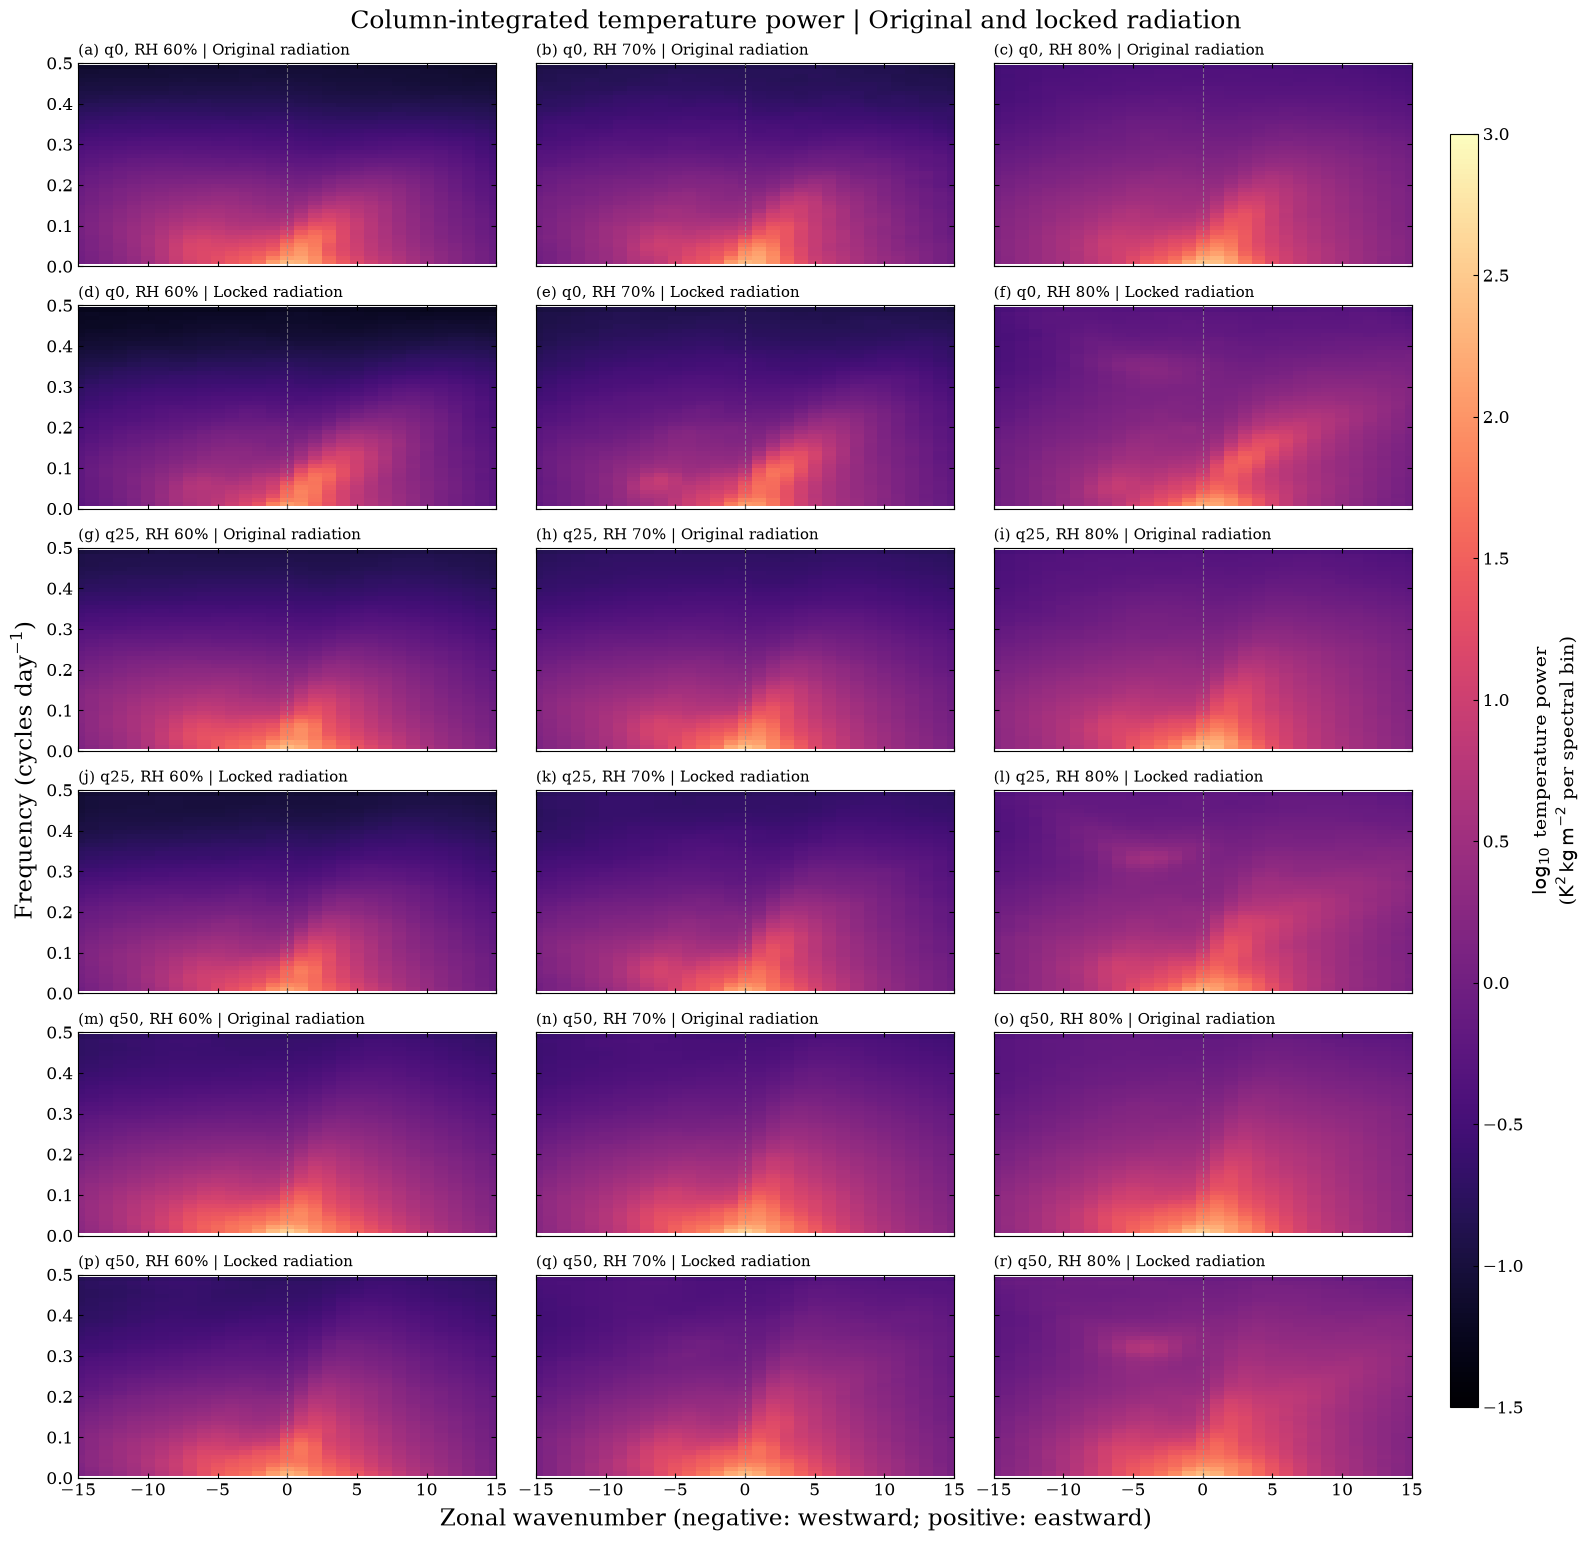

In [5]:
absolute_panels = {
    ((qflux, rad), rh): log_temp_power[name]
    for (qflux, rh, rad), name in experiment_lookup.items()
}
absolute_titles = {
    ((qflux, rad), rh): f"q{qflux}, RH {rh}% | {radiation_labels.get(rad, rad)}"
    for qflux, rh, rad in experiment_lookup
}
comparison_rows = [(qflux, rad) for qflux in qflux_values for rad in radiation_keys]

visible_power = displayed_values(absolute_panels.values())
if LOG10_LIMITS is None:
    vmin = np.floor(2 * visible_power.min()) / 2
    vmax = max(np.ceil(2 * visible_power.max()) / 2, vmin + 0.5)
else:
    vmin, vmax = LOG10_LIMITS
    if not (np.isfinite(vmin) and np.isfinite(vmax) and vmin < vmax):
        raise ValueError("LOG10_LIMITS must contain finite, increasing values")
power_norm = Normalize(vmin=vmin, vmax=vmax)

fig, axes = plot_spectrum_grid(
    absolute_panels, absolute_titles, comparison_rows, rh_values,
    title="Column-integrated temperature power | Original and locked radiation",
    cmap=CMAP, norm=power_norm,
    colorbar_label=(r"$\log_{10}$ temperature power" + "\n"
                    + r"($\mathrm{K^2\,kg\,m^{-2}}$ per spectral bin)"),
)

## Locked-minus-original difference in log10 temperature power

Match experiments with the **same qflux and RH** and calculate the difference
from their folded positive-frequency power:

$$
\Delta\log_{10} P_T
= \log_{10} P_{T,\mathrm{locked}} - \log_{10} P_{T,\mathrm{original}}
= \log_{10}\!\left(\frac{P_{T,\mathrm{locked}}}{P_{T,\mathrm{original}}}\right).
$$

This is the difference of logarithms. The same power units cancel, leaving a
dimensionless log ratio in decades. Red indicates greater locked-radiation
power; blue indicates smaller locked-radiation power. A value of +0.301
means approximately twice the original power; -0.301 means half.

Rows are qflux and columns are RH. All cases share one diverging scale
centered at zero. A bin is masked if either experiment has invalid or
nonpositive power. `log_power_difference[(qflux, rh)]` retains the complete
positive-frequency/wavenumber domain; display limits only crop the figure.
Unmatched cases are reported and omitted.

Black contours overlay $\log_{10} P_{T,\mathrm{original}}$ from the
`boriginal` experiment with the same qflux and RH as each difference panel.
Labels give the original log10 power, with the same power units as the
absolute spectra. Every panel uses the same contour levels, configured
with `ORIGINAL_CONTOUR_LEVELS`; contours use the same folded positive-
frequency spectra and display limits as the shading.

Calculated locked-minus-original log10 power for 9 cases


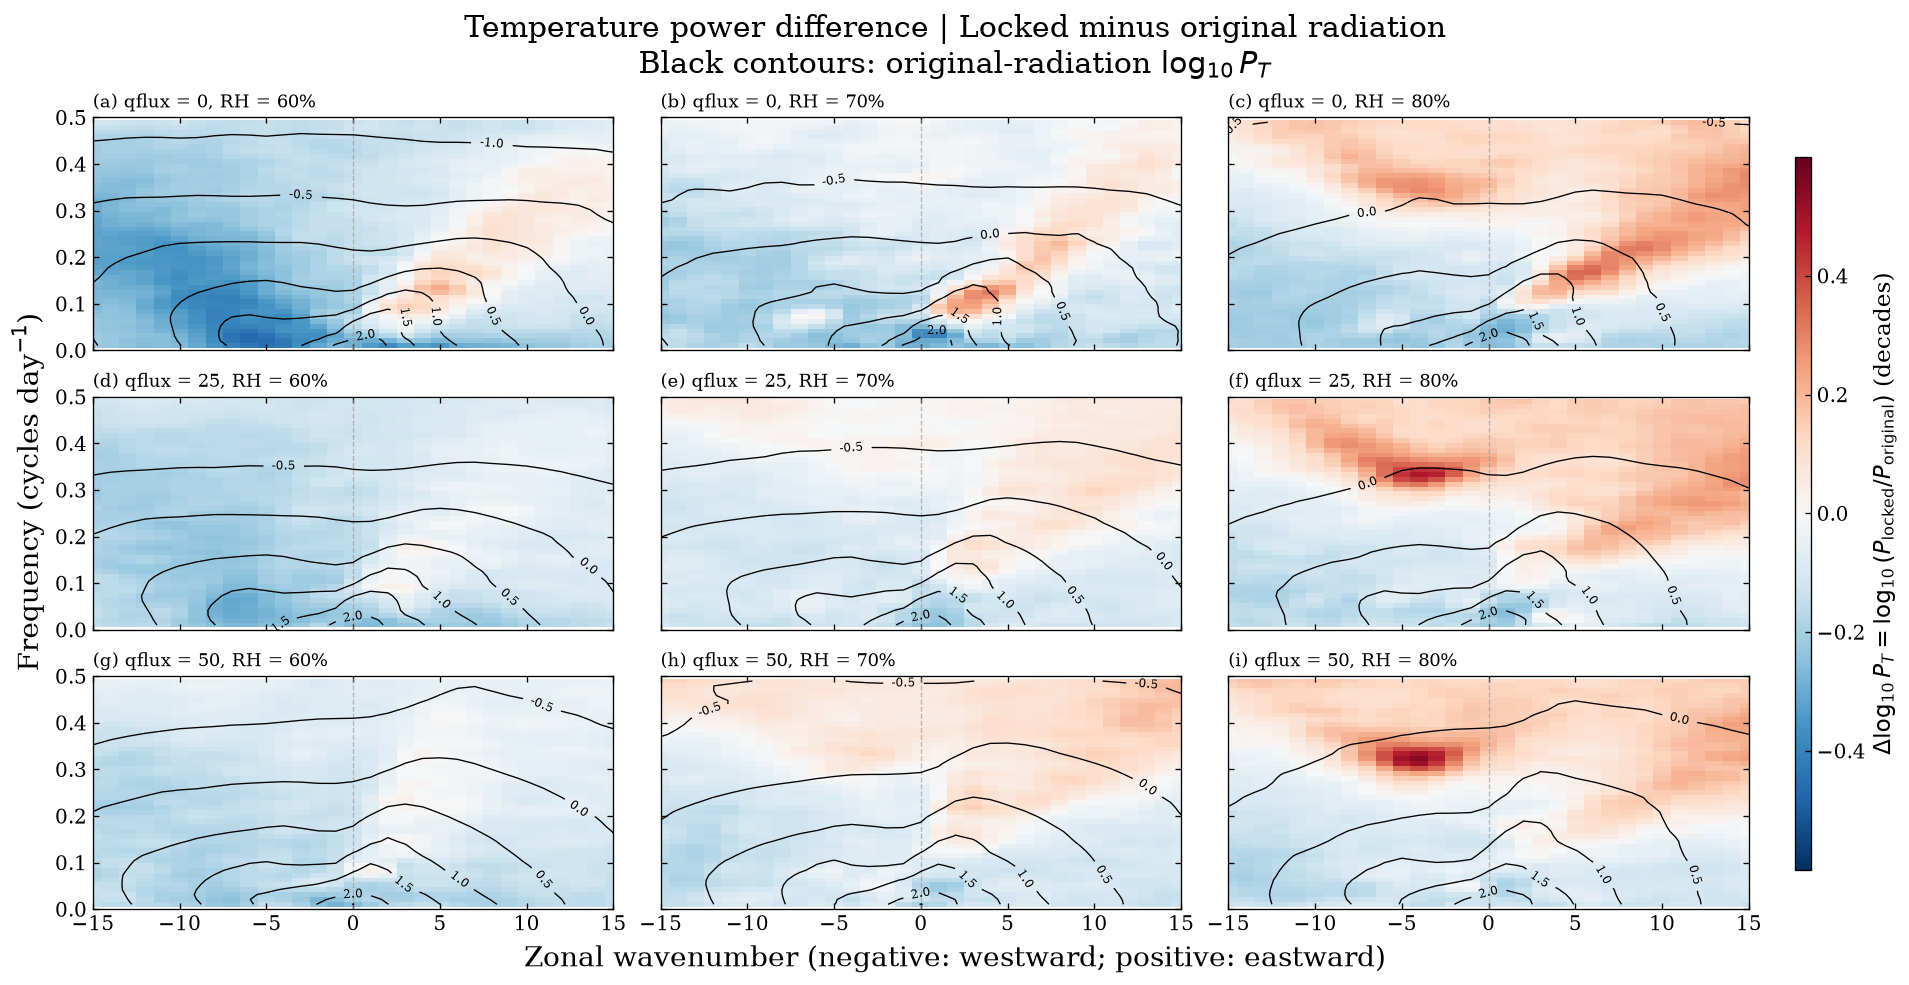

In [6]:
log_power_difference = {}
experiment_pairs = {}
unmatched_cases = []
for qflux in qflux_values:
    for rh in rh_values:
        original = experiment_lookup.get((qflux, rh, "original"))
        locked = experiment_lookup.get((qflux, rh, "_lock"))
        if original is None or locked is None:
            unmatched_cases.append((qflux, rh))
            continue
        case = (qflux, rh)
        log_power_difference[case] = log_temp_power[locked] - log_temp_power[original]
        experiment_pairs[case] = {"locked": locked, "original": original}

if unmatched_cases:
    print(f"Omitted cases without both radiation settings: {unmatched_cases}")
if not log_power_difference:
    raise ValueError("No matching locked/original experiment pairs selected")
print(f"Calculated locked-minus-original log10 power for {len(log_power_difference)} cases")

visible_difference = displayed_values(log_power_difference.values())
if DIFFERENCE_LIMIT is None:
    difference_limit = max(np.ceil(10 * np.abs(visible_difference).max()) / 10, 0.1)
else:
    difference_limit = float(DIFFERENCE_LIMIT)
    if not np.isfinite(difference_limit) or difference_limit <= 0:
        raise ValueError("DIFFERENCE_LIMIT must be finite and positive")
difference_norm = TwoSlopeNorm(vmin=-difference_limit, vcenter=0, vmax=difference_limit)

original_power_contours = {
    case: log_temp_power[pair["original"]]
    for case, pair in experiment_pairs.items()
}
if ORIGINAL_CONTOUR_LEVELS is None:
    visible_original = displayed_values(original_power_contours.values())
    original_contour_levels = np.arange(
        np.floor(2 * visible_original.min()) / 2,
        np.ceil(2 * visible_original.max()) / 2 + 0.25, 0.5,
    )
else:
    original_contour_levels = np.asarray(ORIGINAL_CONTOUR_LEVELS, dtype=float)
    if (original_contour_levels.ndim != 1 or original_contour_levels.size == 0
            or not np.all(np.isfinite(original_contour_levels))
            or np.any(np.diff(original_contour_levels) <= 0)):
        raise ValueError("ORIGINAL_CONTOUR_LEVELS must be finite and strictly increasing")

difference_titles = {
    (qflux, rh): f"qflux = {qflux}, RH = {rh}%"
    for qflux, rh in log_power_difference
}
difference_fig, difference_axes = plot_spectrum_grid(
    log_power_difference, difference_titles, qflux_values, rh_values,
    title=("Temperature power difference | Locked minus original radiation\n"
           + r"Black contours: original-radiation $\log_{10} P_T$"),
    cmap=DIFFERENCE_CMAP, norm=difference_norm,
    colorbar_label=r"$\Delta\log_{10} P_T = \log_{10}(P_{\rm locked}/P_{\rm original})$ (decades)",
    panel_contours=original_power_contours, contour_levels=original_contour_levels,
)

## Save figures and the calculated differences

Both figures are exported at 300 dpi. The NPZ stores the complete difference
array with dimensions `(qflux, rh, frequency, wavenumber)`, its coordinates,
and JSON metadata recording the definition and source experiment pairs.
Masked or unmatched bins are saved as NaN. The original experiment archives
are unchanged.

In [7]:
FIGURE_DIR = DATAPATH.parents[1] / "Figure" / "PowerSpec_EAPE"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_PATH = FIGURE_DIR / "temperature_power_comparison.png"
DIFFERENCE_FIGURE_PATH = FIGURE_DIR / "temperature_log_power_difference.png"
fig.savefig(FIGURE_PATH, dpi=300, bbox_inches="tight")
difference_fig.savefig(DIFFERENCE_FIGURE_PATH, dpi=300, bbox_inches="tight")

# Save full-domain differences, independent of the plot limits.
difference_array = np.full(
    (len(qflux_values), len(rh_values), positive_freq.size, wnum.size), np.nan
)
for (qflux, rh), values in log_power_difference.items():
    difference_array[qflux_values.index(qflux), rh_values.index(rh)] = values.filled(np.nan)

difference_metadata = {
    "definition": "log10(P_locked) - log10(P_original) = log10(P_locked / P_original)",
    "units": "decades (dimensionless log10 ratio)",
    "dimensions": ["qflux", "rh", "frequency", "wavenumber"],
    "frequency_units": "cycles day-1",
    "power_preparation": "P_plus(f,k) = P(f,k) + P(-f,-k), f > 0; DC and temporal Nyquist excluded",
    "experiment_pairs": [
        {"qflux": qflux, "rh": rh, **pair}
        for (qflux, rh), pair in experiment_pairs.items()
    ],
}
DIFFERENCE_DATA_PATH = DATAPATH / "temperature_log_power_difference.npz"
np.savez_compressed(
    DIFFERENCE_DATA_PATH,
    qflux=np.asarray(qflux_values, dtype=float),
    rh=np.asarray(rh_values, dtype=float),
    frequency=positive_freq, wavenumber=wnum,
    log10_power_difference=difference_array,
    metadata=np.array(json.dumps(difference_metadata)),
)
for output_path in (FIGURE_PATH, DIFFERENCE_FIGURE_PATH, DIFFERENCE_DATA_PATH):
    print(f"Saved {output_path}")

Saved /home/b11209013/Isca_analysis/Figure/PowerSpec_EAPE/temperature_power_comparison.png
Saved /home/b11209013/Isca_analysis/Figure/PowerSpec_EAPE/temperature_log_power_difference.png
Saved /home/b11209013/Isca_analysis/Output/EAPE_budget/temperature_log_power_difference.npz


## Heating contributions to modal EAPE growth: sigma1 and sigma2

The saved growth rates are
$\sigma_i = 2\,\mathrm{Re}(C_{QT,i})/P_{TT,i}$, in day⁻¹. Positive values
indicate generation by heating; negative values indicate damping.

Select the saved **strictly positive frequency bins directly**. Growth rates
are ratios, so their values are neither added across conjugate bins nor
log-transformed. Preserve zero and negative rates, and mask only nonfinite
values, including the existing low-temperature-power cutoff. Mode numbers
identify the heating EOF rank within each experiment.

`SIGMA_LIMITS` sets the symmetric display range for each mode. The default
±10 day⁻¹ follows the project's earlier growth-rate figures; colorbar arrows
mark values beyond the display range. `SIGMA_DIFFERENCE_LIMITS` independently
controls the difference figures. `None` uses the full displayed range for
that mode, rounded outward to 5 day⁻¹. Every experiment or case within a
figure shares its normalization. The settings only affect colors; exported
values retain their full magnitude.

In [8]:
SIGMA_LIMITS = {1: 10.0, 2: 10.0}          # day^-1; None selects the full range.
SIGMA_DIFFERENCE_LIMITS = {1: None, 2: None}
SIGMA_CMAP = "RdBu_r"                     # Blue: negative; red: positive.

sigma_positive = {}
for mode, saved_sigma in {1: sigma1, 2: sigma2}.items():
    sigma_positive[mode] = {}
    for name in EXPERIMENTS:
        values = saved_sigma[name]
        if values.shape != (freq.size, wnum.size):
            raise ValueError(f"Unexpected sigma{mode} shape for {name}")
        sigma_positive[mode][name] = np.ma.masked_invalid(values[pos_freq, :])


def sigma_normalization(fields, limit):
    """Symmetric zero-centered scale; use the same limit for all panels."""
    if limit is None:
        values = displayed_values(fields)
        limit = max(5 * np.ceil(np.abs(values).max() / 5), 1.0)
    limit = float(limit)
    if not np.isfinite(limit) or limit <= 0:
        raise ValueError("Sigma color limits must be finite and positive, or None")
    return TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)

## Sigma1 and sigma2 in every experiment

Each mode has an 18-panel figure using the temperature-power layout:
RH 60%, 70%, and 80% in columns, with paired original/locked radiation rows
for qflux 0, 25, and 50. The default color scale is identical for both modes.

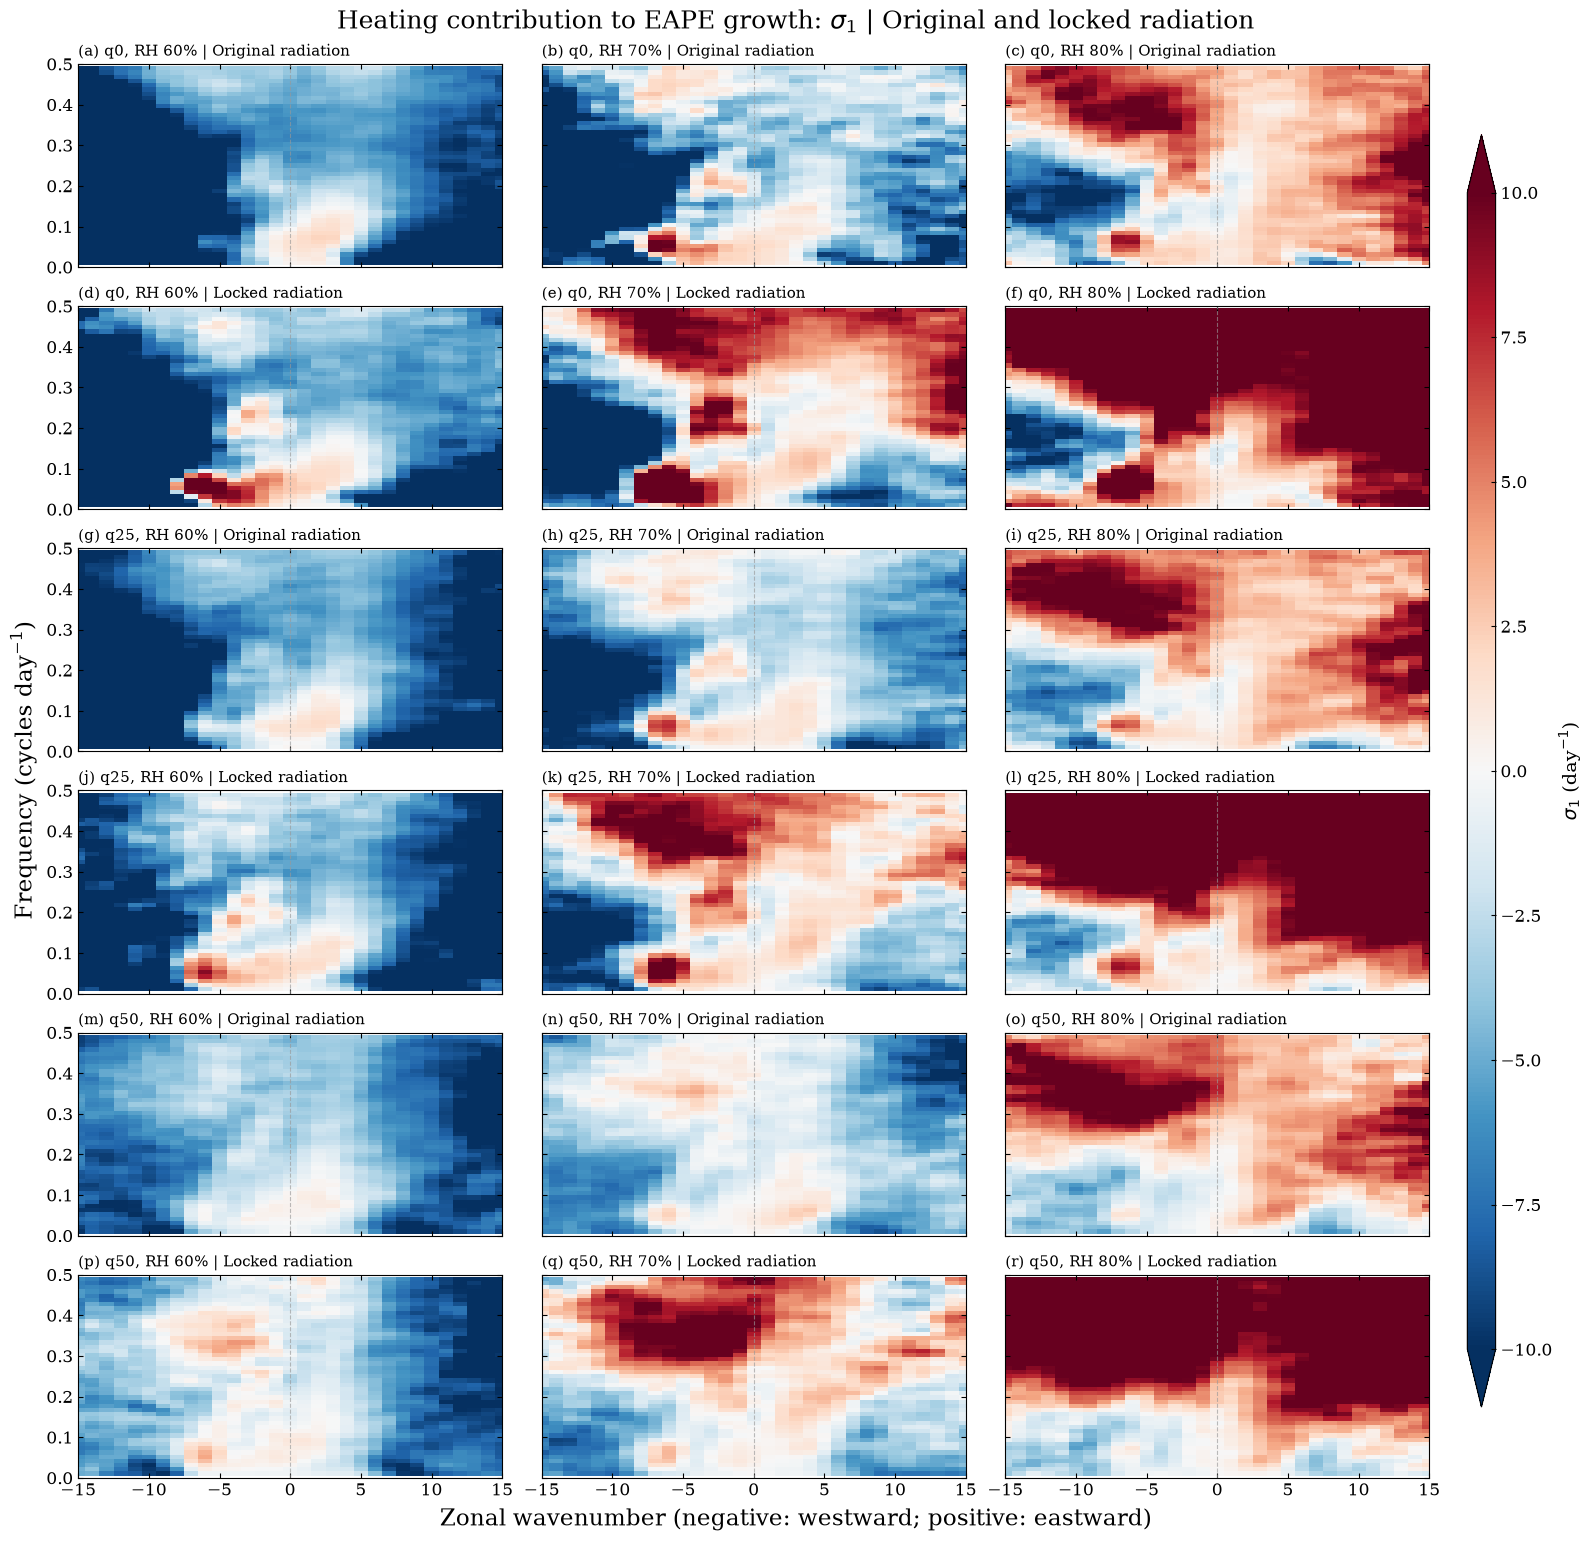

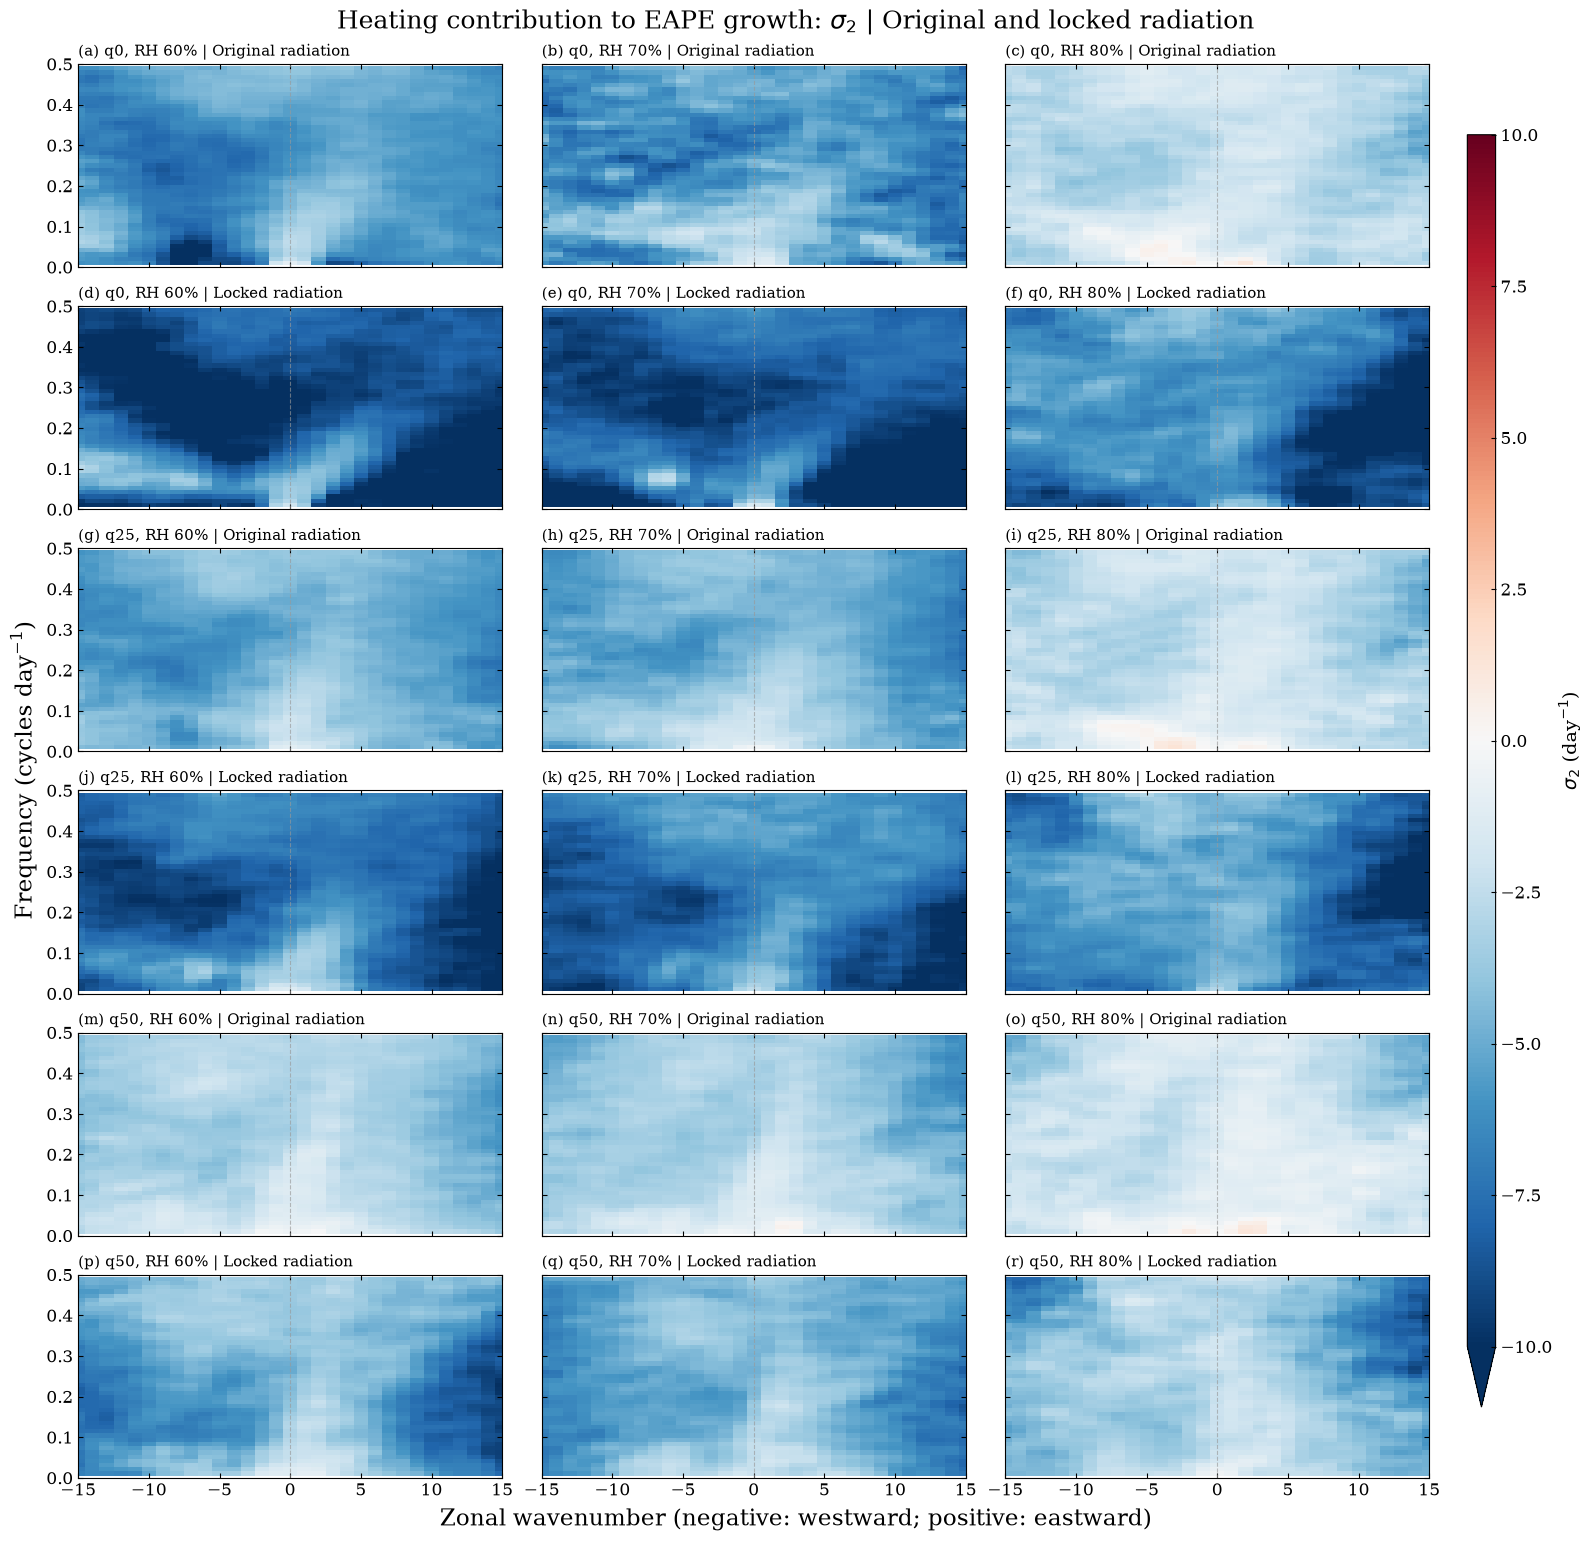

In [9]:
sigma_figures = {}
sigma_norms = {}
for mode in (1, 2):
    panels = {
        ((qflux, rad), rh): sigma_positive[mode][name]
        for (qflux, rh, rad), name in experiment_lookup.items()
    }
    sigma_norms[mode] = sigma_normalization(panels.values(), SIGMA_LIMITS[mode])
    sigma_figures[mode], _ = plot_spectrum_grid(
        panels, absolute_titles, comparison_rows, rh_values,
        title=fr"Heating contribution to EAPE growth: $\sigma_{mode}$ | Original and locked radiation",
        cmap=SIGMA_CMAP, norm=sigma_norms[mode],
        colorbar_label=fr"$\sigma_{mode}$ (day$^{{-1}}$)",
    )

## Locked-minus-original differences in sigma1 and sigma2

For each matching qflux/RH pair, calculate the direct growth-rate difference:

$$
\Delta\sigma_i(f,k)
= \sigma_{i,\mathrm{locked}}(f,k) - \sigma_{i,\mathrm{original}}(f,k),
\qquad i=1,2.
$$

The units remain day⁻¹. Red means the heating contribution is more positive
under locked radiation; blue means it is more negative. A positive difference
can reflect weaker damping as well as stronger generation. Each mode has a
3 × 3 figure with qflux rows and RH columns. A difference is masked wherever
either input rate is nonfinite. Pairing uses the same experiment matches as
the temperature-power differences.

`sigma_difference[mode][(qflux, rh)]` retains the full positive-frequency and
wavenumber domain, independent of the display limits.

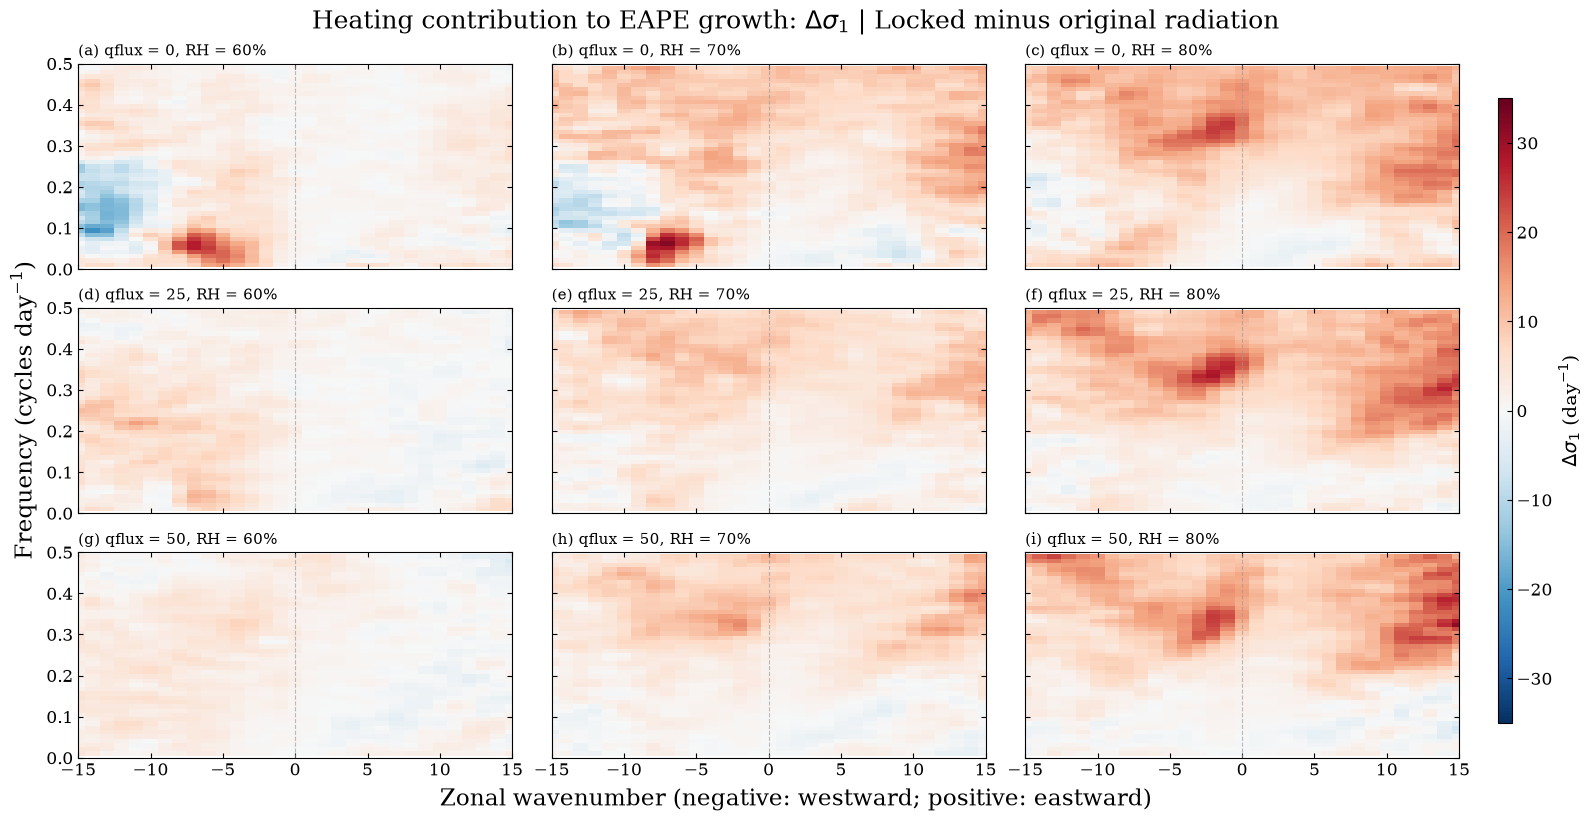

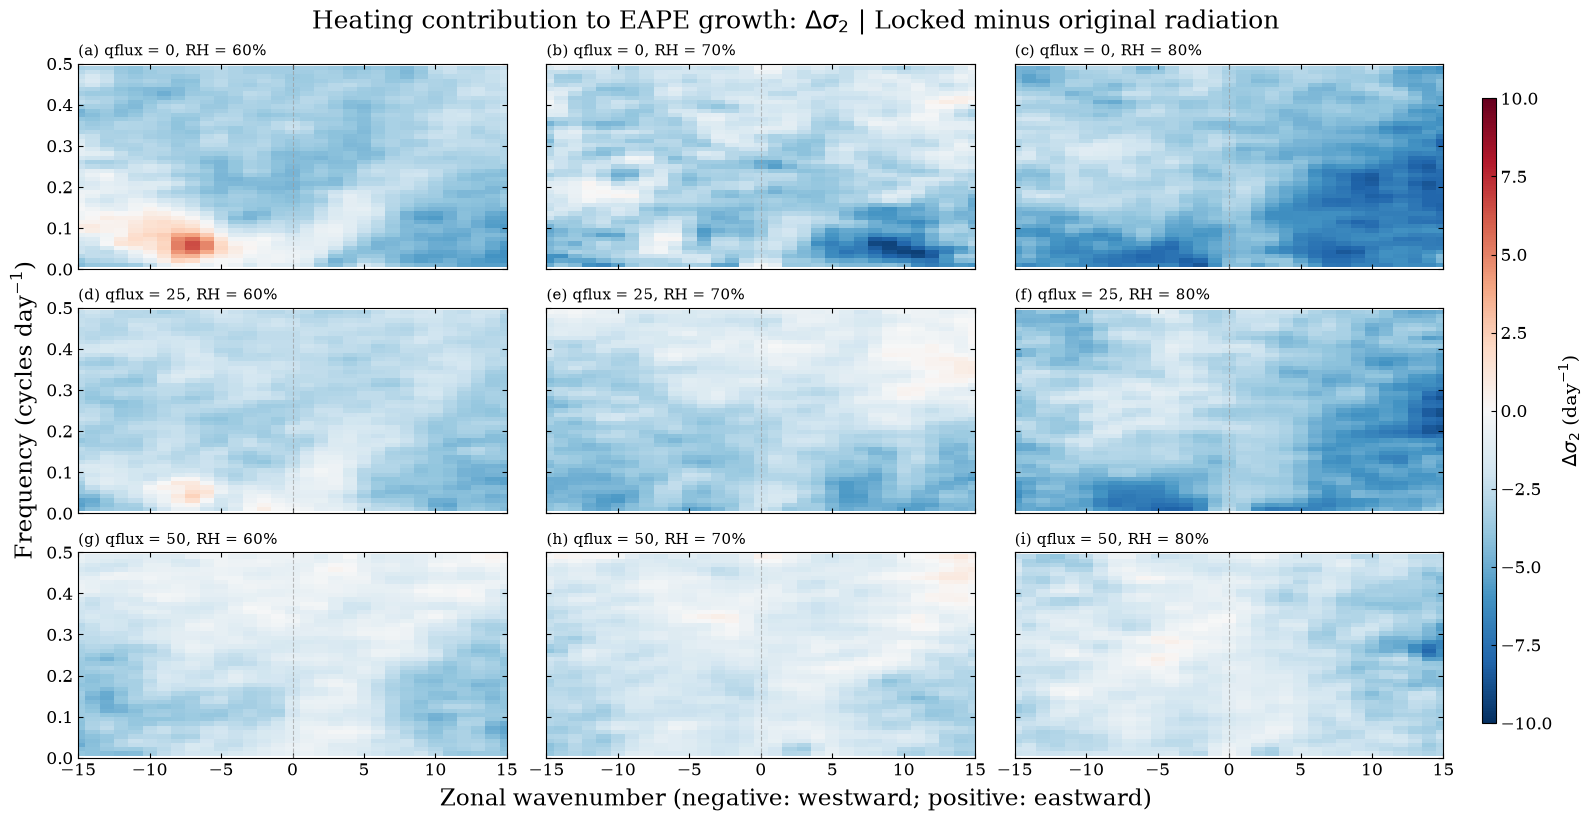

Calculated sigma1 and sigma2 differences for 9 matched cases


In [10]:
sigma_difference = {}
sigma_difference_figures = {}
sigma_difference_norms = {}
for mode in (1, 2):
    sigma_difference[mode] = {
        case: np.ma.masked_invalid(
            sigma_positive[mode][pair["locked"]]
            - sigma_positive[mode][pair["original"]]
        )
        for case, pair in experiment_pairs.items()
    }
    sigma_difference_norms[mode] = sigma_normalization(
        sigma_difference[mode].values(), SIGMA_DIFFERENCE_LIMITS[mode]
    )
    sigma_difference_figures[mode], _ = plot_spectrum_grid(
        sigma_difference[mode], difference_titles, qflux_values, rh_values,
        title=fr"Heating contribution to EAPE growth: $\Delta\sigma_{mode}$ | Locked minus original radiation",
        cmap=SIGMA_CMAP, norm=sigma_difference_norms[mode],
        colorbar_label=fr"$\Delta\sigma_{mode}$ (day$^{{-1}}$)",
    )

print(f"Calculated sigma1 and sigma2 differences for {len(experiment_pairs)} matched cases")

## Save sigma figures and calculated differences

The four sigma figures are exported at 300 dpi. The NPZ contains
`sigma_difference` with dimensions `(mode, qflux, rh, frequency, wavenumber)`,
all coordinates, units, and the matched source experiments. Masked and
unmatched bins are stored as NaN. No display clipping is applied to these
numerical differences.

In [11]:
SIGMA_FIGURE_PATHS = {}
for mode in (1, 2):
    for suffix, figure in (
        ("comparison", sigma_figures[mode]),
        ("locked_minus_original", sigma_difference_figures[mode]),
    ):
        output_path = FIGURE_DIR / f"sigma{mode}_{suffix}.png"
        figure.savefig(output_path, dpi=300, bbox_inches="tight")
        SIGMA_FIGURE_PATHS[(mode, suffix)] = output_path
        print(f"Saved {output_path}")

sigma_difference_array = np.full(
    (2, len(qflux_values), len(rh_values), positive_freq.size, wnum.size), np.nan
)
for mode in (1, 2):
    for (qflux, rh), values in sigma_difference[mode].items():
        sigma_difference_array[
            mode - 1, qflux_values.index(qflux), rh_values.index(rh)
        ] = values.filled(np.nan)

sigma_difference_metadata = {
    "definition": "sigma_i_locked - sigma_i_original, for each heating EOF rank i",
    "units": "day-1",
    "dimensions": ["mode", "qflux", "rh", "frequency", "wavenumber"],
    "mode_definition": "Heating EOF rank within each experiment",
    "frequency_units": "cycles day-1",
    "preparation": "Saved growth rates selected at f > 0; no conjugate summation, doubling, or logarithm",
    "missing_values": "NaN wherever either source rate is nonfinite, or no matched pair exists",
    "experiment_pairs": difference_metadata["experiment_pairs"],
}
SIGMA_DIFFERENCE_DATA_PATH = DATAPATH / "sigma_locked_minus_original.npz"
np.savez_compressed(
    SIGMA_DIFFERENCE_DATA_PATH,
    mode=np.array([1, 2]),
    qflux=np.asarray(qflux_values, dtype=float),
    rh=np.asarray(rh_values, dtype=float),
    frequency=positive_freq, wavenumber=wnum,
    sigma_difference=sigma_difference_array,
    metadata=np.array(json.dumps(sigma_difference_metadata)),
)
print(f"Saved {SIGMA_DIFFERENCE_DATA_PATH}")

Saved /home/b11209013/Isca_analysis/Figure/PowerSpec_EAPE/sigma1_comparison.png


Saved /home/b11209013/Isca_analysis/Figure/PowerSpec_EAPE/sigma1_locked_minus_original.png


Saved /home/b11209013/Isca_analysis/Figure/PowerSpec_EAPE/sigma2_comparison.png


Saved /home/b11209013/Isca_analysis/Figure/PowerSpec_EAPE/sigma2_locked_minus_original.png
Saved /home/b11209013/Isca_analysis/Output/EAPE_budget/sigma_locked_minus_original.npz
